# Tugas 1 - Klasifikasi Wine Quality dengan KNN
  
| Nama              | NRP        |
|Fauzan Tamma Harish Kunfaza|5054251035|
|              |       |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Wine Quality Dataset. Dataset bisa diakses melalui link berikut:\
🔗 https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

Tujuan utama dari tugas ini adalah membangun model K-Nearest Neighbors (KNN) untuk mengklasifikasikan kualitas wine. 

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset & Eksplorasi Awal

- Memuat dataset, melihat struktur data, dan distribusi label.

2. Preprocessing 
- Memproses data agar siap untuk digunakan dalam membangun model.

3. Eksperimen Model KNN
- Bangun model KNN dengan mencoba beberapa nilai k (misalnya 3, 5, dan 7 --> BEBAS) serta dua metric jarak (seperti Euclidean dan Manhattan).
- Eksperimen ini bertujuan untuk membandingkan performa KNN dengan parameter yang berbeda.

4. Evaluasi Model
- Hitung metrik evaluasi seperti Accuracy, Precision, Recall, F1-Score, serta visualisasikan Confusion Matrix.

5. Analisis & Kesimpulan
- Bandingkan hasil antar eksperimen yang telah dilakukan dan berikan kesimpulan.


# 1. Persiapan Dataset & Eksplorasi Awal

In [3]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

Ukuran dataset: (1143, 13)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB

Statistik deskriptif:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


Nama kolom:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Tipe data:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object
Jumlah missing value pada setiap kolom:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id   

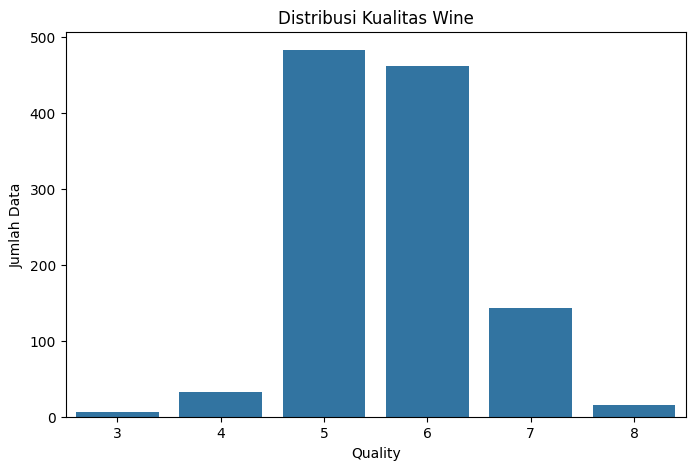

In [4]:
#  Load Dataset dan menampilkan informasi dasar tentang dataset, seperti jumlah baris dan kolom, tipe data, jumlah nilai yang hilang, dan informasi lainnya yang dibutuhkan.

# Load dataset
data = pd.read_csv('WineQT.csv')

# Menampilkan 5 data pertama
data.head()

print("Ukuran dataset:", data.shape)

print("\nInformasi dataset:")
data.info()

print("\nStatistik deskriptif:")
display(data.describe())

print("Nama kolom:")
print(data.columns.tolist())

print("\nTipe data:")
print(data.dtypes)

# Mengecek missing value
missing_values = data.isnull().sum()

print("Jumlah missing value pada setiap kolom:")
print(missing_values)

# Mengecek data duplikat
print("Jumlah data duplikat:", data.duplicated().sum())

# Distribusi label quality
print("Distribusi quality:")
print(data['quality'].value_counts().sort_index())

# Visualisasi distribusi quality
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='quality'
)

plt.title('Distribusi Kualitas Wine')
plt.xlabel('Quality')
plt.ylabel('Jumlah Data')
plt.show()

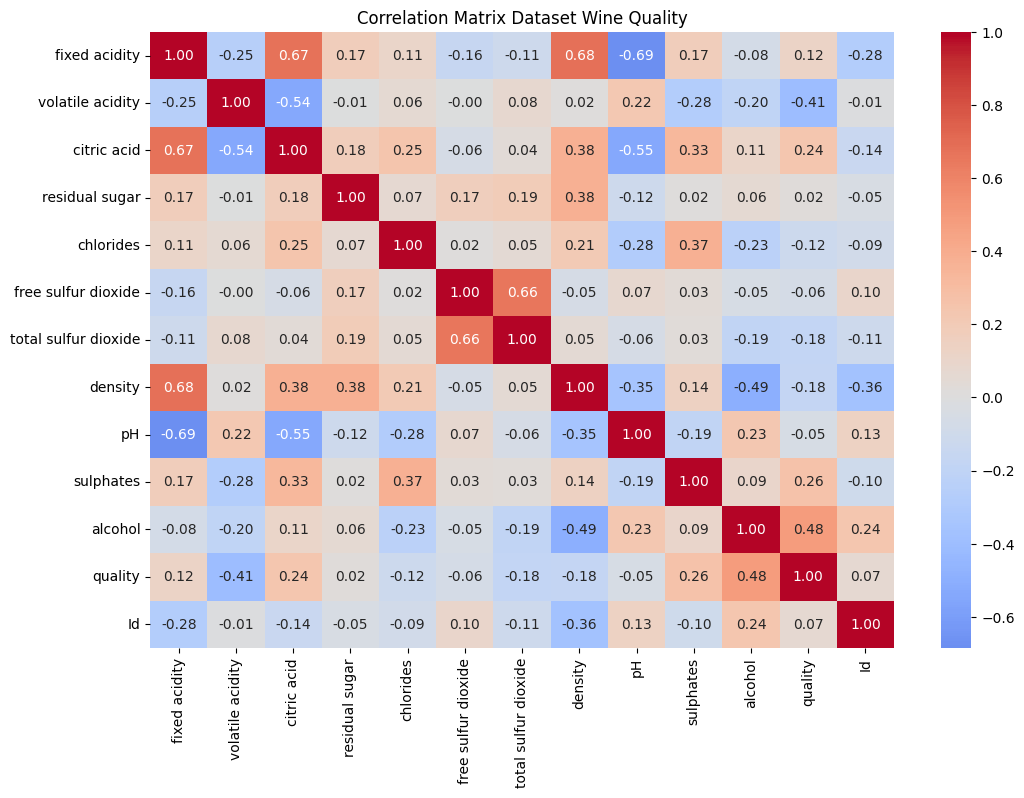

In [5]:
# Tampilkan Korelasi Matrix
# Menghitung korelasi antar variabel
correlation = data.corr(numeric_only=True)

# Visualisasi correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix Dataset Wine Quality')
plt.show()

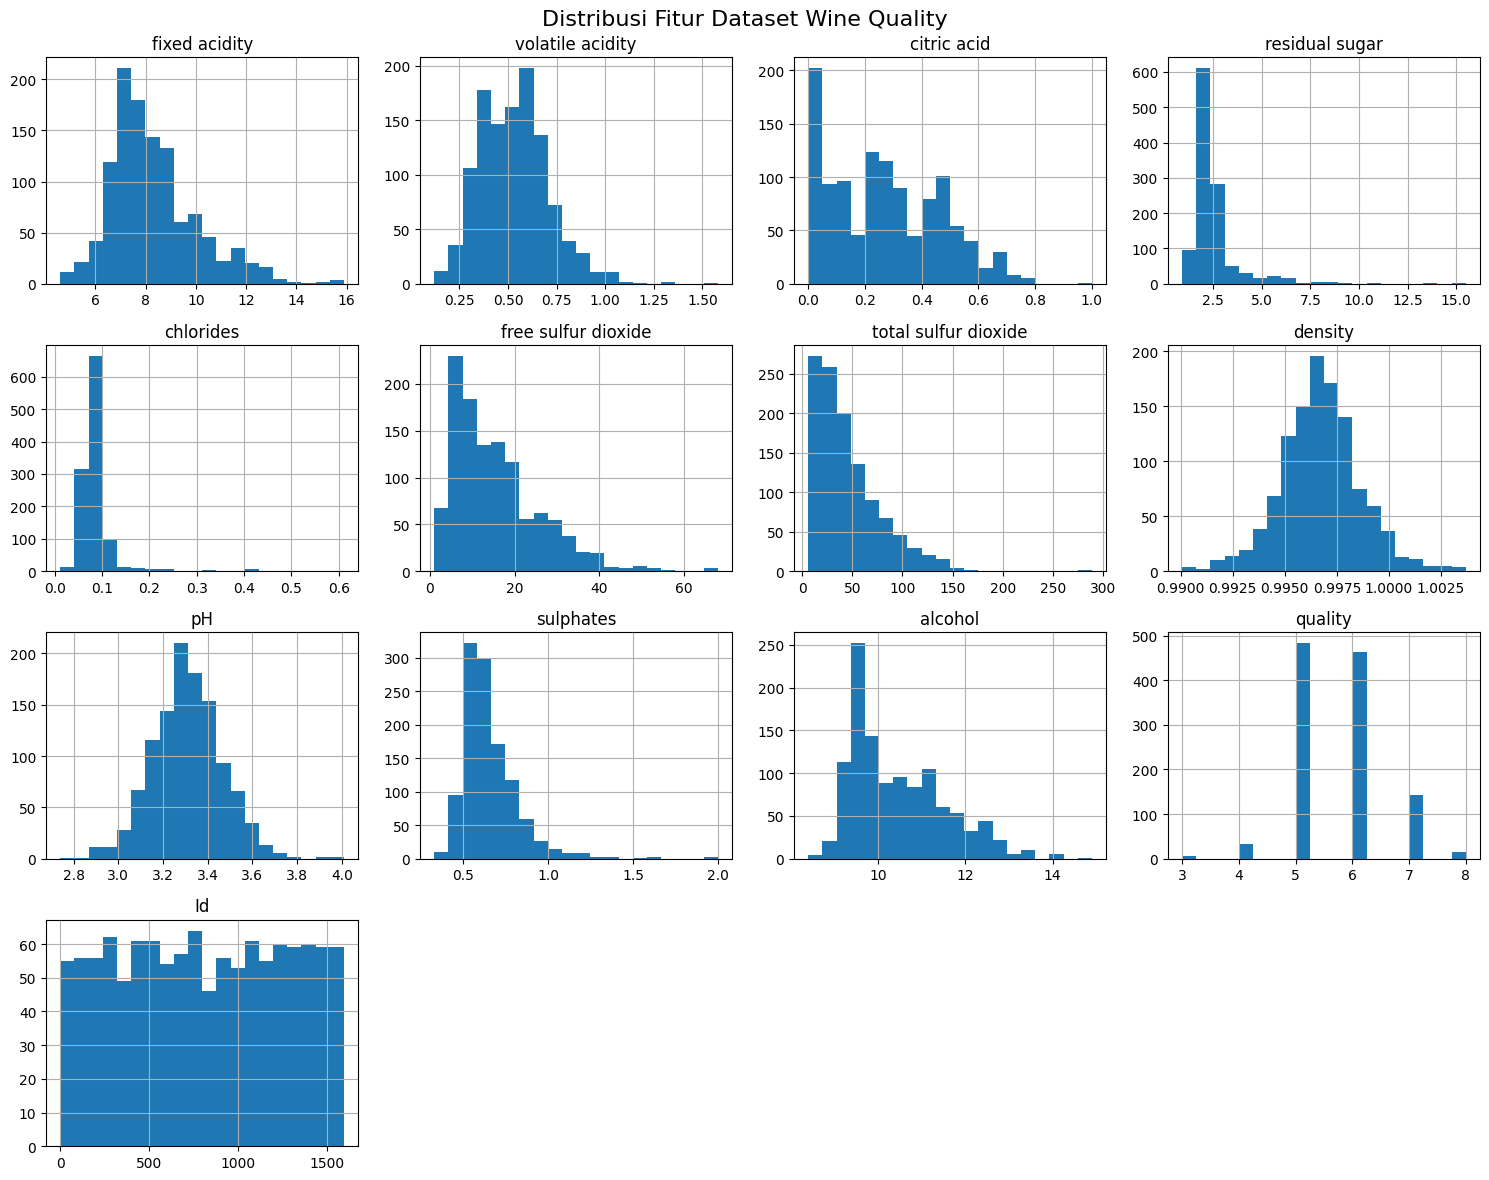

In [6]:
# Tampilkan distribusi label (quality) dalam bentuk visualisasi, misalnya menggunakan histogram atau bar plot.
# Histogram
data.hist(figsize=(15, 12), bins=20)

plt.suptitle(
    'Distribusi Fitur Dataset Wine Quality',
    fontsize=16
)

plt.tight_layout()
plt.show()

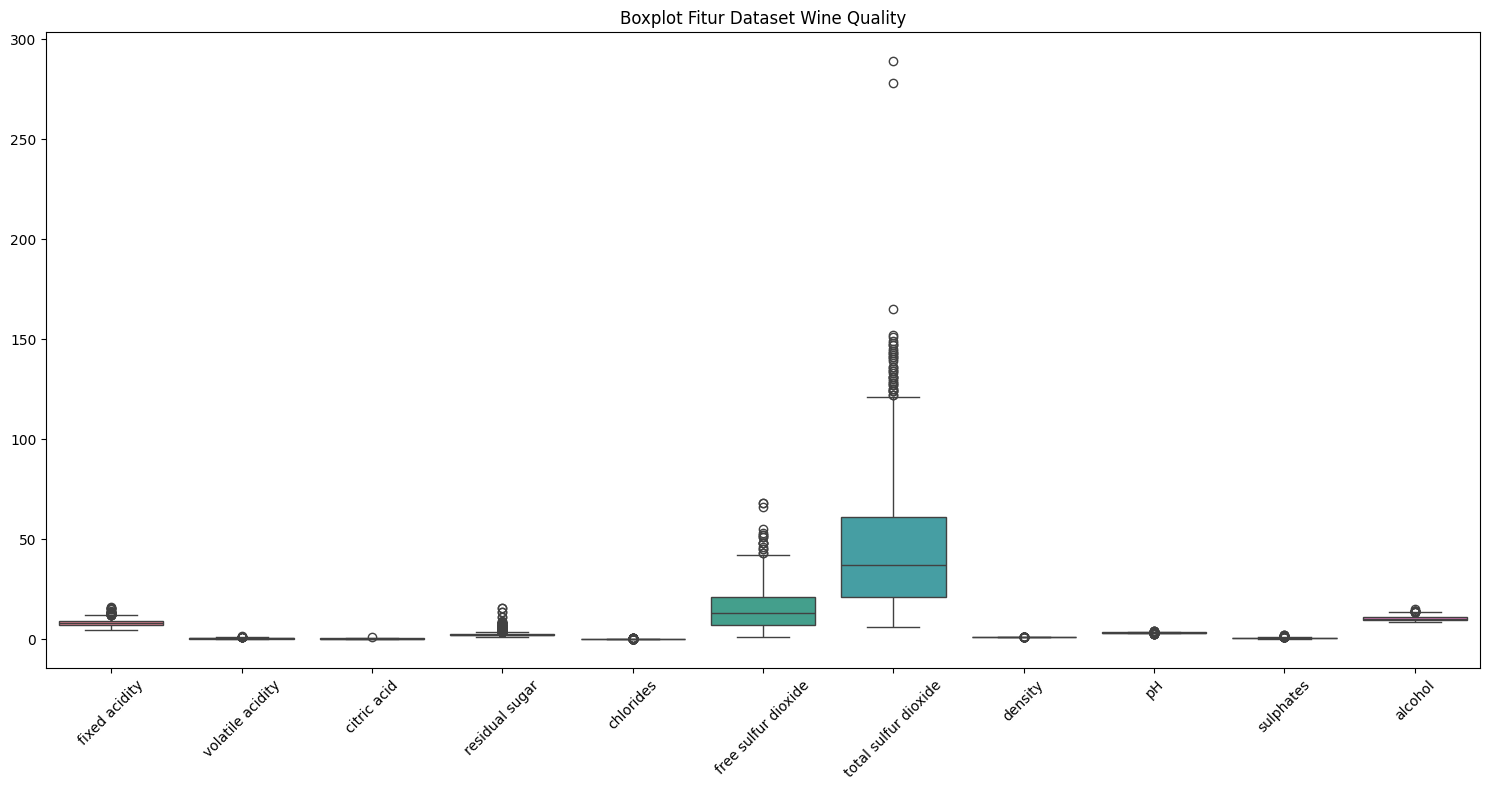

In [7]:
# Boxplot fitur numerik
plt.figure(figsize=(15, 8))

sns.boxplot(data=data.drop(columns=['quality', 'Id']))

plt.title('Boxplot Fitur Dataset Wine Quality')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Silahkan Lakukan Exploratory Data Analysis (EDA) tambahan yang dibutuhkan. 

# 2. Preprocessing




In [8]:
# NaN handling (drop, impute, etc.), duplicate handling, dan lain-lain.
# Mengecek missing value
print("Jumlah missing value setiap kolom:")
print(data.isnull().sum())

# Mengecek dan menangani data duplikat
jumlah_duplicate = data.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplicate)

data = data.drop_duplicates().reset_index(drop=True)

print("Ukuran dataset setelah proses duplicate:", data.shape)

Jumlah missing value setiap kolom:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64
Jumlah data duplikat: 0
Ukuran dataset setelah proses duplicate: (1143, 13)


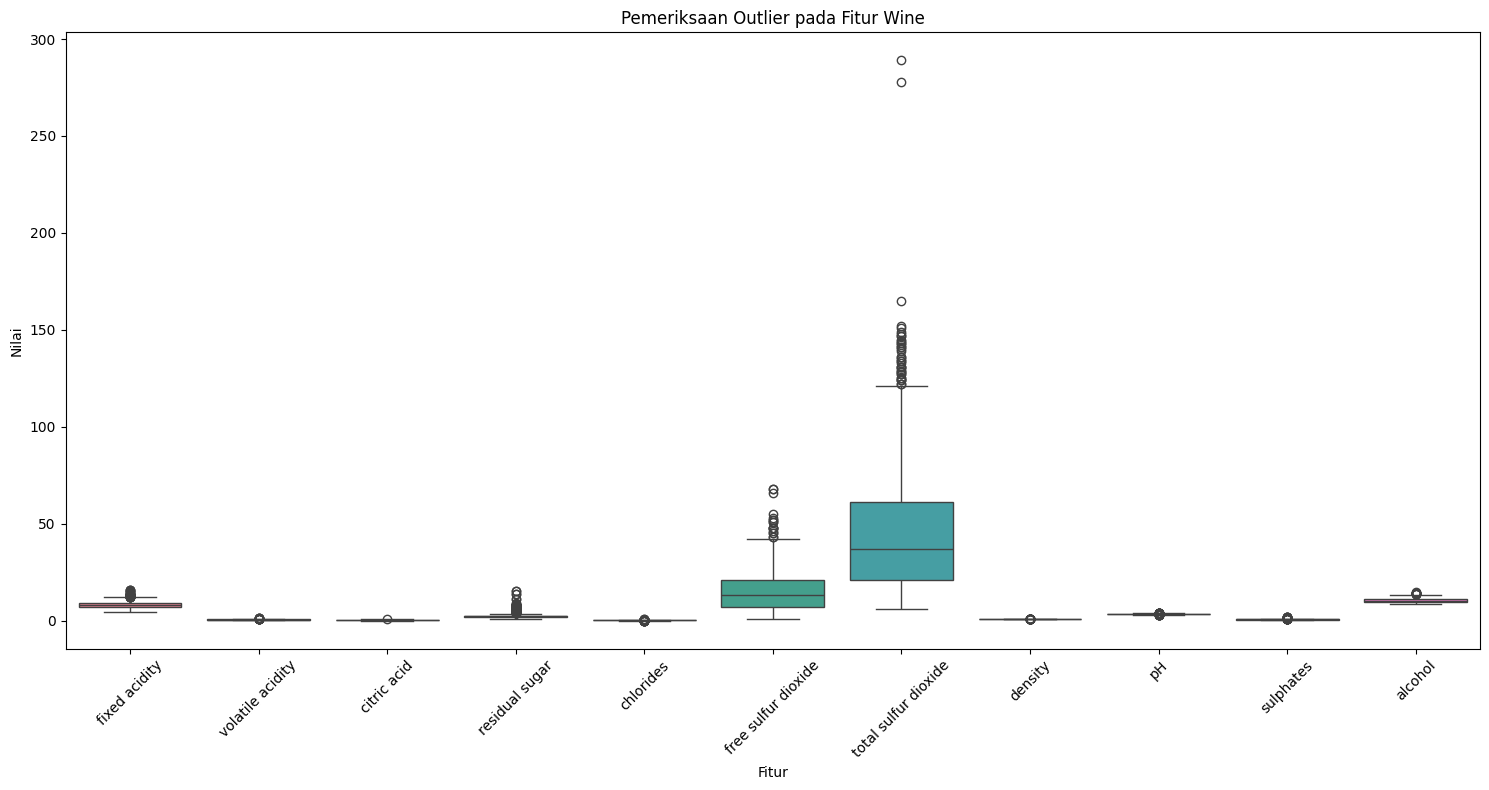

In [9]:
# Periksa Outliers (jika diperlukan), misalnya menggunakan boxplot atau metode statistik lainnya. (Bisa dilakukan eksperimen dengan dan tanpa outlier untuk melihat perbedaan performa model)
# Pemeriksaan outlier menggunakan boxplot
features = data.drop(columns=['quality', 'Id'])

plt.figure(figsize=(15, 8))

sns.boxplot(data=features)

plt.title('Pemeriksaan Outlier pada Fitur Wine')
plt.xlabel('Fitur')
plt.ylabel('Nilai')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
# Scaling data (jika diperlukan), misalnya menggunakan StandardScaler atau MinMaxScaler. (Bisa dilakukan eksperimen dengan dan tanpa scaling untuk melihat perbedaan performa model)
# Perhatikan data leakage saat melakukan scaling. Scaling harus dilakukan setelah membagi data menjadi train dan test set.

# Memisahkan fitur dan target

X = data.drop(columns=['quality', 'Id'])
y = data['quality']

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

# Memastikan tidak terdapat missing value pada X dan y
print("Missing value pada X:")
print(X.isnull().sum().sum())

print("\nMissing value pada y:")
print(y.isnull().sum())

print("\nJumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

Ukuran X: (1143, 11)
Ukuran y: (1143,)
Missing value pada X:
0

Missing value pada y:
0

Jumlah fitur: 11
Jumlah data: 1143


# 3. Eksperimen Model KNN


In [11]:
# Split data menjadi train dan test set. (misal 80% train, 20% test)
# Gunakan fungsi train_test_split dari sklearn.model_selection untuk membagi data menjadi train dan test set. Pastikan untuk memisahkan fitur (X) dan label (y) sebelum melakukan split.
# Gunakan stratify=y agar distribusi label pada train dan test set tetap sama dengan distribusi label pada dataset asli.
# Train model KNN menggunakan train set. Gunakan fungsi KNeighborsClassifier dari sklearn.neighbors untuk membuat model KNN. Lakukan eksperimen dengan berbagai nilai k (misal k=1, 3, 5, 7, 9) dan catat performa model pada train set dan test set.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Membagi data menjadi training set dan testing set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

# Standardisasi fitur
scaler = StandardScaler()

# Fit scaler hanya pada data training
X_train_scaled = scaler.fit_transform(X_train)

# Gunakan scaler yang sama untuk data testing
X_test_scaled = scaler.transform(X_test)

print("Scaling berhasil dilakukan.")

Ukuran X_train: (914, 11)
Ukuran X_test : (229, 11)
Ukuran y_train: (914,)
Ukuran y_test : (229,)
Scaling berhasil dilakukan.


In [23]:
# Daftar nilai K yang akan diuji
k_values = [1, 3, 5, 7, 9]

# Daftar metric yang akan diuji
metrics = ['euclidean', 'manhattan']

# Menyimpan hasil eksperimen
results = []

for metric in metrics:
    for k in k_values:

        # Membuat model KNN
        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric
        )

        # Training model
        knn.fit(X_train_scaled, y_train)

        # Prediksi data training dan testing
        y_train_pred = knn.predict(X_train_scaled)
        y_test_pred = knn.predict(X_test_scaled)

        # Menghitung accuracy
        train_accuracy = accuracy_score(y_train, y_train_pred)
        test_accuracy = accuracy_score(y_test, y_test_pred)

        # Menyimpan hasil
        results.append({
            'K': k,
            'Metric': metric,
            'Train Accuracy': train_accuracy,
            'Test Accuracy': test_accuracy
        })

# Mengubah hasil menjadi DataFrame
results_df = pd.DataFrame(results)

results_df

,K,Metric,Train Accuracy,Test Accuracy
0,1,euclidean,1.000000,0.650655
1,3,euclidean,0.759300,0.606987
2,5,euclidean,0.683807,0.576419
3,7,euclidean,0.663020,0.593886
4,9,euclidean,0.640044,0.620087
5,1,manhattan,1.000000,0.659389
6,3,manhattan,0.746171,0.567686
7,5,manhattan,0.691466,0.585153
8,7,manhattan,0.664114,0.611354
9,9,manhattan,0.647702,0.659389


In [24]:
# Menampilkan accuracy dalam persen
results_display = results_df.copy()

results_display['Train Accuracy'] = (
    results_display['Train Accuracy'] * 100
).round(2)

results_display['Test Accuracy'] = (
    results_display['Test Accuracy'] * 100
).round(2)

results_display

,K,Metric,Train Accuracy,Test Accuracy
0,1,euclidean,100.00,65.07
1,3,euclidean,75.93,60.70
2,5,euclidean,68.38,57.64
3,7,euclidean,66.30,59.39
4,9,euclidean,64.00,62.01
5,1,manhattan,100.00,65.94
6,3,manhattan,74.62,56.77
7,5,manhattan,69.15,58.52
8,7,manhattan,66.41,61.14
9,9,manhattan,64.77,65.94


In [26]:
best_model = results_df.loc[
    results_df['Test Accuracy'].idxmax()
]

print("Model terbaik berdasarkan Test Accuracy:")
print(best_model)

Model terbaik berdasarkan Test Accuracy:
K                         1
Metric            manhattan
Train Accuracy          1.0
Test Accuracy      0.659389
Name: 5, dtype: object


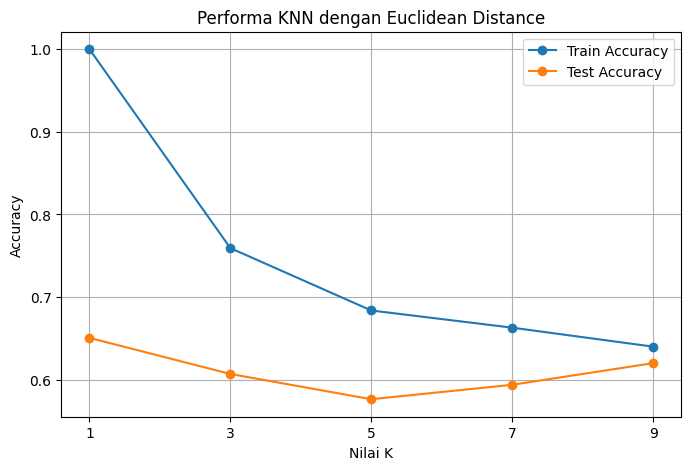

In [27]:
euclidean_results = results_df[
    results_df['Metric'] == 'euclidean'
]

plt.figure(figsize=(8, 5))

plt.plot(
    euclidean_results['K'],
    euclidean_results['Train Accuracy'],
    marker='o',
    label='Train Accuracy'
)

plt.plot(
    euclidean_results['K'],
    euclidean_results['Test Accuracy'],
    marker='o',
    label='Test Accuracy'
)

plt.xlabel('Nilai K')
plt.ylabel('Accuracy')
plt.title('Performa KNN dengan Euclidean Distance')
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()

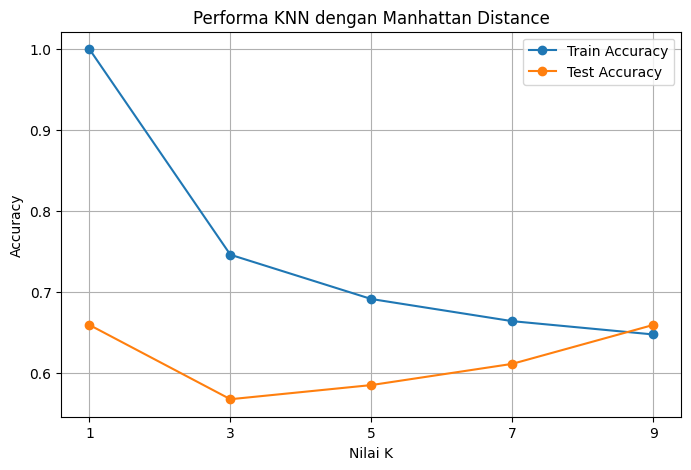

In [28]:
manhattan_results = results_df[
    results_df['Metric'] == 'manhattan'
]

plt.figure(figsize=(8, 5))

plt.plot(
    manhattan_results['K'],
    manhattan_results['Train Accuracy'],
    marker='o',
    label='Train Accuracy'
)

plt.plot(
    manhattan_results['K'],
    manhattan_results['Test Accuracy'],
    marker='o',
    label='Test Accuracy'
)

plt.xlabel('Nilai K')
plt.ylabel('Accuracy')
plt.title('Performa KNN dengan Manhattan Distance')
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()

# 4. Evaluasi Model


In [ ]:
# Tampilkan evaluasi model KNN dengan metriks evaluasi yang sesuai dengan tipe masalah klasifikasi
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# Nilai K dan metric yang akan dievaluasi
k_values = [1, 3, 5, 7, 9]
metrics = ['euclidean', 'manhattan']

# Menyimpan hasil evaluasi
evaluation_results = []

for metric in metrics:
    for k in k_values:

        # Membuat model KNN
        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric
        )

        # Training model
        knn.fit(X_train_scaled, y_train)

        # Prediksi data testing
        y_test_pred = knn.predict(X_test_scaled)

        # Menghitung metrik evaluasi
        accuracy = accuracy_score(y_test, y_test_pred)

        precision = precision_score(
            y_test,
            y_test_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_test_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_test_pred,
            average='weighted',
            zero_division=0
        )

        # Menyimpan hasil
        evaluation_results.append({
            'K': k,
            'Metric': metric,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1
        })

# Mengubah hasil menjadi DataFrame
evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

In [ ]:
# Membuat tabel evaluasi dalam bentuk persentase
evaluation_display = evaluation_df.copy()

metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

evaluation_display[metric_columns] = (
    evaluation_display[metric_columns] * 100
).round(2)

evaluation_display

In [ ]:
best_model_result = evaluation_df.loc[
    evaluation_df['F1-Score'].idxmax()
]

print("Model terbaik berdasarkan F1-Score:")
print(best_model_result)

In [ ]:
# Mengambil parameter model terbaik
best_k = int(best_model_result['K'])
best_metric = best_model_result['Metric']

print("K terbaik:", best_k)
print("Metric terbaik:", best_metric)

In [ ]:
# Membuat model terbaik
best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric=best_metric
)

best_knn.fit(X_train_scaled, y_train)

# Prediksi data testing
y_best_pred = best_knn.predict(X_test_scaled)

In [ ]:
# Membuat confusion matrix
cm = confusion_matrix(y_test, y_best_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title(
    f'Confusion Matrix KNN (K={best_k}, {best_metric})'
)

plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')

plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        y_best_pred,
        zero_division=0
    )
)

Evaluasi Model

Evaluasi dilakukan terhadap seluruh konfigurasi KNN yang telah diuji sebelumnya, yaitu kombinasi nilai K = 1, 3, 5, 7, dan 9 dengan Euclidean dan Manhattan Distance. Metrik yang digunakan adalah Accuracy, Precision, Recall, dan F1-Score.

Karena variabel target quality memiliki lebih dari dua kelas dan jumlah data pada setiap kelas tidak sama, Precision, Recall, dan F1-Score dihitung menggunakan pendekatan weighted average. Pendekatan ini mempertimbangkan jumlah sampel pada masing-masing kelas dalam menghasilkan nilai evaluasi keseluruhan.

Selain metrik numerik, Confusion Matrix digunakan untuk melihat distribusi prediksi model pada masing-masing kelas quality. Model terbaik kemudian dipilih berdasarkan hasil F1-Score dan dianalisis lebih lanjut menggunakan Confusion Matrix serta Classification Report.

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen model KNN yang telah dilakukan. Bandingkan hasil antar eksperimen yang telah dilakukan. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.  

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.